<a href="https://colab.research.google.com/github/Myrella669/SIN393-Classificacao-Clima/blob/main/Classificacao-Clima_codigo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os

os.environ['KAGGLE_API_TOKEN'] = 'COLE_SEU_TOKEN_AQUI'
print("Token do Kaggle configurado com sucesso!")

!kaggle datasets download -d jehanbhathena/weather-dataset
!mkdir -p dataset
!unzip -q weather-dataset.zip -d dataset

print("Dataset baixado e descompactado com sucesso!")

Token do Kaggle configurado com sucesso!
Dataset URL: https://www.kaggle.com/datasets/jehanbhathena/weather-dataset
License(s): CC0-1.0
100% 587M/587M [00:04<00:00, 125MB/s]

Dataset baixado e descompactado com sucesso!


In [2]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo em uso: {device}")

pasta_correta = 'dataset'
for root, dirs, files in os.walk('dataset'):
    if len(dirs) > 5:
        pasta_correta = root
        break

print(f"A pasta correta com as imagens é: {pasta_correta}")

Dispositivo em uso: cuda
A pasta correta com as imagens é: dataset/dataset


In [3]:
from torchvision import datasets, transforms

image_size = 224

train_transforms = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

full_dataset_train = datasets.ImageFolder(pasta_correta, transform=train_transforms)
full_dataset_val_test = datasets.ImageFolder(pasta_correta, transform=val_test_transforms)

class_names = full_dataset_train.classes
num_classes = len(class_names)
print(f"Classes detetadas ({num_classes}): {class_names}")

Classes detetadas (11): ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']


In [4]:
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader

targets = full_dataset_train.targets

train_idx, temp_idx, _, temp_targets = train_test_split(
    np.arange(len(targets)), targets, test_size=0.3, stratify=targets, random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5, stratify=temp_targets, random_state=42
)

train_dataset = Subset(full_dataset_train, train_idx)
val_dataset = Subset(full_dataset_val_test, val_idx)
test_dataset = Subset(full_dataset_val_test, test_idx)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Total de imagens no Treino: {len(train_dataset)}")
print(f"Total de imagens na Validação: {len(val_dataset)}")
print(f"Total de imagens no Teste: {len(test_dataset)}")

Total de imagens no Treino: 4803
Total de imagens na Validação: 1029
Total de imagens no Teste: 1030


In [5]:
import torch.nn as nn
from torchvision import models

print("A transferir e a configurar a ResNet18...")
weights_resnet = models.ResNet18_Weights.DEFAULT
model_resnet = models.resnet18(weights=weights_resnet)
model_resnet.fc = nn.Linear(model_resnet.fc.in_features, num_classes)
model_resnet = model_resnet.to(device)

print("A transferir e a configurar a EfficientNet-B0...")
weights_efficient = models.EfficientNet_B0_Weights.DEFAULT
model_efficientnet = models.efficientnet_b0(weights=weights_efficient)
model_efficientnet.classifier[1] = nn.Linear(model_efficientnet.classifier[1].in_features, num_classes)
model_efficientnet = model_efficientnet.to(device)

print("Modelos carregados e movidos para a GPU com sucesso!")

A transferir e a configurar a ResNet18...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 152MB/s]


A transferir e a configurar a EfficientNet-B0...
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 121MB/s] 


Modelos carregados e movidos para a GPU com sucesso!


In [6]:
import torch.optim as optim
import time
import copy

criterion = nn.CrossEntropyLoss()

def train_model(model, optimizer, num_epochs=5):
    since = time.time()
    best_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f'Época {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                dataloader = train_loader
            else:
                model.eval()
                dataloader = val_loader

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloader.dataset)
            epoch_acc = running_corrects.double() / len(dataloader.dataset)

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'train':
                history['train_loss'].append(epoch_loss)
                history['train_acc'].append(epoch_acc.item())
            else:
                history['val_loss'].append(epoch_loss)
                history['val_acc'].append(epoch_acc.item())

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
        print()

    time_elapsed = time.time() - since
    print(f'Treinamento completo em {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Melhor Acurácia de Validação: {best_acc:.4f}')

    model.load_state_dict(best_model_wts)
    return model, history

print("Função de treinamento pronta!")

Função de treinamento pronta!


In [7]:
print("Iniciando o treinamento da ResNet18...")
optimizer_resnet = optim.Adam(model_resnet.parameters(), lr=0.001)
model_resnet, hist_resnet = train_model(model_resnet, optimizer_resnet, num_epochs=5)

print("\nIniciando o treinamento da EfficientNet-B0...")
optimizer_efficient = optim.Adam(model_efficientnet.parameters(), lr=0.001)
model_efficientnet, hist_efficient = train_model(model_efficientnet, optimizer_efficient, num_epochs=5)

Iniciando o treinamento da ResNet18...
Época 1/5
----------
Train Loss: 1.0340 Acc: 0.6579
Val Loss: 1.3361 Acc: 0.6453

Época 2/5
----------
Train Loss: 0.6895 Acc: 0.7726
Val Loss: 1.1319 Acc: 0.6744

Época 3/5
----------
Train Loss: 0.6021 Acc: 0.8007
Val Loss: 0.7702 Acc: 0.7570

Época 4/5
----------
Train Loss: 0.5120 Acc: 0.8309
Val Loss: 0.5376 Acc: 0.8309

Época 5/5
----------
Train Loss: 0.4956 Acc: 0.8364
Val Loss: 0.7192 Acc: 0.7804

Treinamento completo em 4m 39s
Melhor Acurácia de Validação: 0.8309

Iniciando o treinamento da EfficientNet-B0...
Época 1/5
----------
Train Loss: 0.6991 Acc: 0.7816
Val Loss: 0.4015 Acc: 0.8630

Época 2/5
----------
Train Loss: 0.4137 Acc: 0.8674
Val Loss: 0.3510 Acc: 0.8834

Época 3/5
----------
Train Loss: 0.3451 Acc: 0.8905
Val Loss: 0.3946 Acc: 0.8805

Época 4/5
----------
Train Loss: 0.2836 Acc: 0.9053
Val Loss: 0.3296 Acc: 0.8921

Época 5/5
----------
Train Loss: 0.2472 Acc: 0.9184
Val Loss: 0.3506 Acc: 0.8853

Treinamento completo em 5m

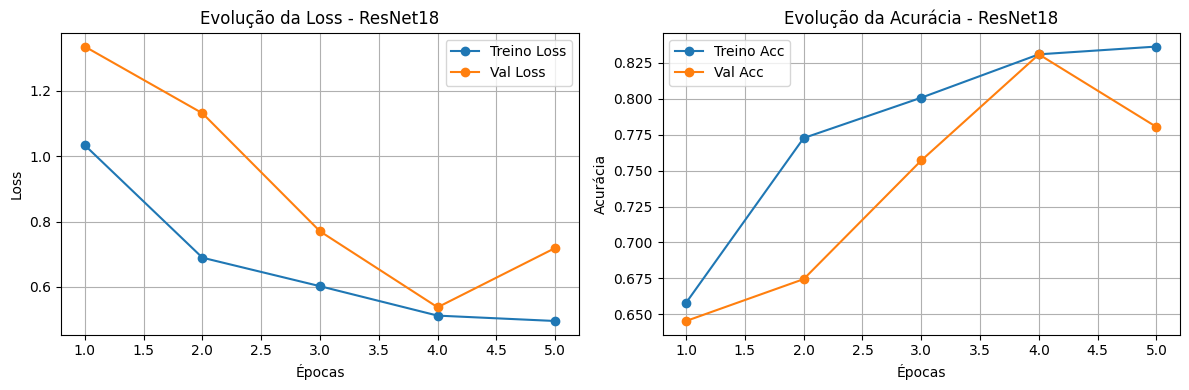

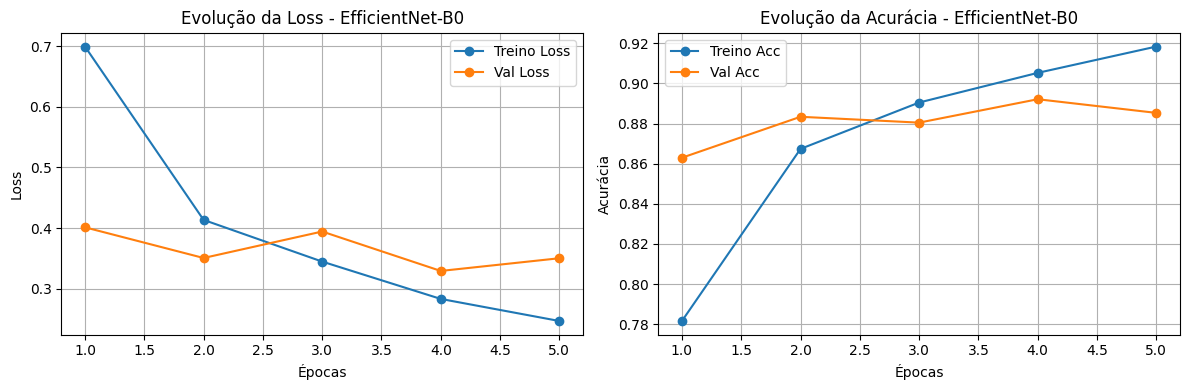

In [8]:
import matplotlib.pyplot as plt

def plot_history(hist, title):
    epochs = range(1, len(hist['train_loss']) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, hist['train_loss'], label='Treino Loss', marker='o')
    plt.plot(epochs, hist['val_loss'], label='Val Loss', marker='o')
    plt.title(f'Evolução da Loss - {title}')
    plt.xlabel('Épocas')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, hist['train_acc'], label='Treino Acc', marker='o')
    plt.plot(epochs, hist['val_acc'], label='Val Acc', marker='o')
    plt.title(f'Evolução da Acurácia - {title}')
    plt.xlabel('Épocas')
    plt.ylabel('Acurácia')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_history(hist_resnet, "ResNet18")
plot_history(hist_efficient, "EfficientNet-B0")

================ Avaliação: ResNet18 ================

              precision    recall  f1-score   support

         dew       0.89      0.89      0.89       105
     fogsmog       0.88      0.94      0.91       128
       frost       0.61      0.80      0.70        71
       glaze       0.74      0.58      0.65        96
        hail       0.88      0.82      0.85        89
   lightning       0.98      0.98      0.98        56
        rain       0.83      0.73      0.78        79
     rainbow       1.00      0.89      0.94        35
        rime       0.78      0.91      0.84       174
   sandstorm       0.93      0.89      0.91       104
        snow       0.77      0.62      0.69        93

    accuracy                           0.83      1030
   macro avg       0.84      0.82      0.83      1030
weighted avg       0.83      0.83      0.83      1030



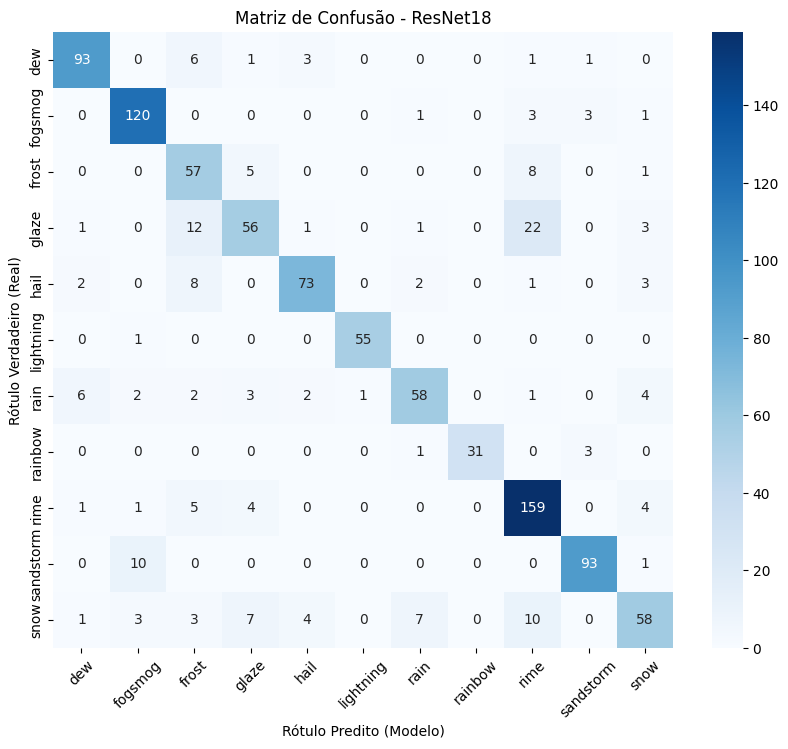

================ Avaliação: EfficientNet-B0 ================

              precision    recall  f1-score   support

         dew       0.98      0.91      0.95       105
     fogsmog       0.93      0.90      0.91       128
       frost       0.69      0.93      0.80        71
       glaze       0.86      0.71      0.78        96
        hail       0.94      0.88      0.91        89
   lightning       1.00      0.96      0.98        56
        rain       0.82      0.90      0.86        79
     rainbow       0.92      1.00      0.96        35
        rime       0.89      0.90      0.89       174
   sandstorm       0.91      0.95      0.93       104
        snow       0.85      0.81      0.83        93

    accuracy                           0.89      1030
   macro avg       0.89      0.89      0.89      1030
weighted avg       0.89      0.89      0.89      1030



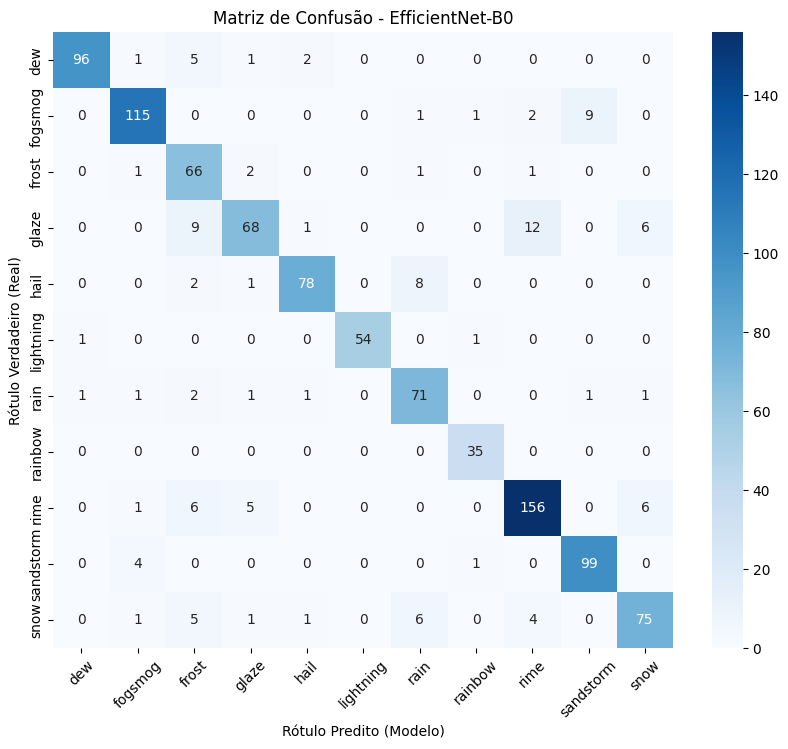

In [9]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

def evaluate_model(model, dataloader, class_names, model_name):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    print(f"================ Avaliação: {model_name} ================\n")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.ylabel('Rótulo Verdadeiro (Real)')
    plt.xlabel('Rótulo Predito (Modelo)')
    plt.title(f'Matriz de Confusão - {model_name}')
    plt.xticks(rotation=45)
    plt.show()

evaluate_model(model_resnet, test_loader, class_names, "ResNet18")
evaluate_model(model_efficientnet, test_loader, class_names, "EfficientNet-B0")

Análise Qualitativa - EfficientNet-B0 (O Melhor Modelo)

--- 4 EXEMPLOS DE ACERTOS ---


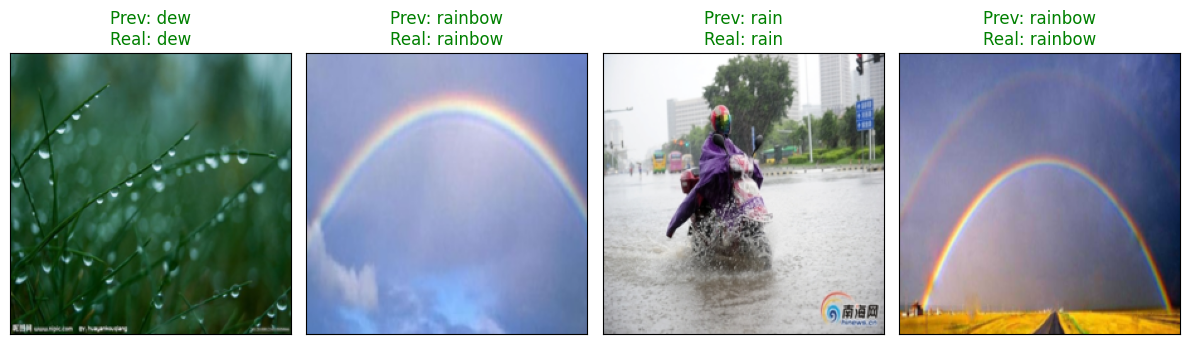


--- 8 EXEMPLOS DE ERROS ---


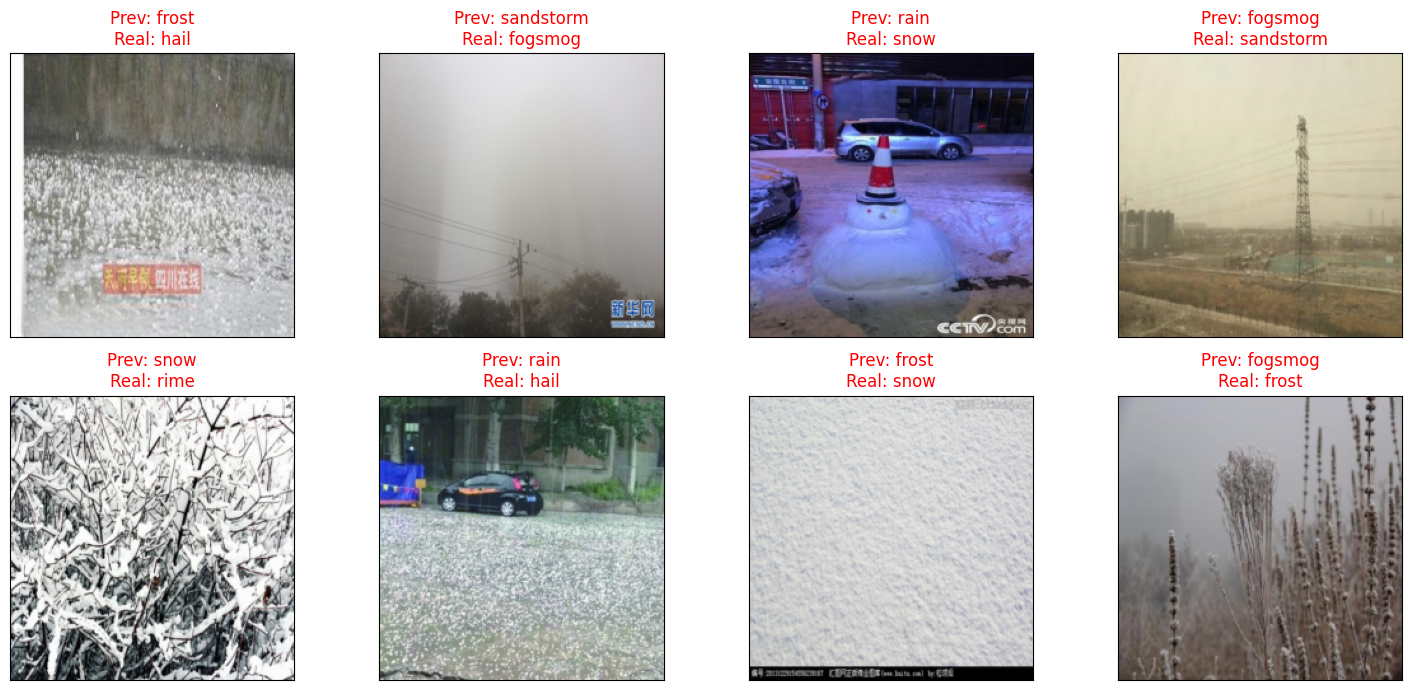

In [10]:
def im_convert(tensor):
    image = tensor.cpu().clone().detach().numpy()
    image = image.transpose(1, 2, 0)
    image = image * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    image = image.clip(0, 1)
    return image

def visualizar_qualitativo(model, dataloader, class_names, num_acertos=4, num_erros=8):
    model.eval()
    corretas = []
    incorretas = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for i in range(inputs.size(0)):
                if preds[i] == labels[i] and len(corretas) < num_acertos:
                    corretas.append((inputs[i], preds[i], labels[i]))
                elif preds[i] != labels[i] and len(incorretas) < num_erros:
                    incorretas.append((inputs[i], preds[i], labels[i]))

                if len(corretas) >= num_acertos and len(incorretas) >= num_erros:
                    break
            if len(corretas) >= num_acertos and len(incorretas) >= num_erros:
                break

    print("\n--- 4 EXEMPLOS DE ACERTOS ---")
    fig = plt.figure(figsize=(12, 4))
    for i, (img, pred, label) in enumerate(corretas):
        ax = fig.add_subplot(1, num_acertos, i + 1, xticks=[], yticks=[])
        ax.imshow(im_convert(img))
        ax.set_title(f'Prev: {class_names[pred]}\nReal: {class_names[label]}', color='green')
    plt.tight_layout()
    plt.show()

    print("\n--- 8 EXEMPLOS DE ERROS ---")
    fig = plt.figure(figsize=(15, 7))
    for i, (img, pred, label) in enumerate(incorretas):
        ax = fig.add_subplot(2, int(num_erros/2), i + 1, xticks=[], yticks=[])
        ax.imshow(im_convert(img))
        ax.set_title(f'Prev: {class_names[pred]}\nReal: {class_names[label]}', color='red')
    plt.tight_layout()
    plt.show()

print("Análise Qualitativa - EfficientNet-B0 (O Melhor Modelo)")
visualizar_qualitativo(model_efficientnet, test_loader, class_names, num_acertos=4, num_erros=8)